# Chapitre 2 - Cours 2 : Taille des modèles, calcul et lois d'échelle

Quand un nouveau modèle sort, la première question est souvent « combien de
paramètres ? ». Ce notebook donne les outils pour répondre, et surtout pour en tirer les
conséquences pratiques : mémoire, coût d'entraînement, choix entre taille du modèle et
quantité de données. Il couvre :

- la fin de la section *Model Architecture* : dimensions d'un transformer (tableau 2-4
  du livre), prefill et decode, architectures alternatives (*Other model architectures* :
  RWKV, SSM, Mamba, Jamba) ;
- la section *Model Size* : paramètres, parcimonie et mélange d'experts, tokens
  d'entraînement, FLOPs, coût ; puis *Scaling law: Building compute-optimal models*
  (Chinchilla), *Scaling extrapolation* et *Scaling bottlenecks*.

**Plan.** 1. Compter les paramètres à partir de la configuration ; 2. Mémoire : poids et
cache KV ; 3. Prefill et decode ; 4. Au-delà du transformer ; 5. Parcimonie et mélange
d'experts ; 6. Tokens, FLOPs et dollars ; 7. La loi de Chinchilla ; 8. Extrapolation et
capacités émergentes ; 9. Les goulots d'étranglement ; Synthèse.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoConfig

from aie import llm
from aie import ch02_modeles as m
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, subtitle, finish)

set_style()
warnings.filterwarnings("ignore", category=FutureWarning)
llm.seed_everything(0)
rng = np.random.default_rng(0)
pd.set_option("display.precision", 2)
sci = lambda v: f"{v:.0e}".replace("e+", "e")   # étiquettes compactes pour les axes log
big = lambda n: f"{n / 1e9:.2f} G" if n >= 1e9 else f"{n / 1e6:.1f} M"

## 1. Compter les paramètres à partir de la configuration (section *Model Architecture*)

La taille d'un transformer décodeur est entièrement fixée par quelques hyperparamètres
(cours 1, section 9) : la dimension du modèle $d$, le nombre de blocs $L$, la dimension
du MLP $d_{ff}$, la taille du vocabulaire $V$, et le nombre de têtes de requêtes $h$ et de
têtes clés-valeurs $h_{kv}$ (avec $d_h = d/h$). En négligeant biais et normalisations :

| composant | paramètres |
|---|---|
| plongements | $V d$ |
| attention, par bloc | $\underbrace{d^2}_{W_Q} + \underbrace{2\,d\,h_{kv} d_h}_{W_K, W_V} + \underbrace{d^2}_{W_O}$ |
| MLP, par bloc | $2\,d\,d_{ff}$ (classique, GPT-2) ou $3\,d\,d_{ff}$ (SwiGLU, Llama, Qwen) |
| tête de sortie | $V d$, ou 0 si elle **partage** la matrice des plongements (*tied*) |

Pour Llama 2-7B ($d = 4096$, $L = 32$, $d_{ff} = 11\,008$, $V = 32\,000$, $h_{kv} = h$) :
$$N \approx 32\,(4 \cdot 4096^2 + 3 \cdot 4096 \cdot 11\,008) + 2 \cdot 32\,000 \cdot 4096
\approx 6{,}48\text{ G} + 0{,}26\text{ G} = 6{,}74 \text{ milliards}.$$

La fonction `m.count_params_config` implémente le calcul exact (biais et normalisations
compris). Vérifions-la contre les **vrais fichiers de poids** de nos modèles locaux : on lit
uniquement les en-têtes des fichiers `safetensors` (formes des tenseurs), sans charger le
modèle en mémoire.

In [2]:
rows = []
for mid in ["gpt2", "Qwen/Qwen2.5-0.5B", llm.SMALL, llm.MEDIUM]:
    cfg = m.config_from_hf(AutoConfig.from_pretrained(mid), name=mid)
    n_cfg, n_file = m.count_params_config(cfg), m.count_params_safetensors(mid)
    rows.append(dict(modèle=mid, d=cfg.d_model, L=cfg.n_layers, d_ff=cfg.d_ff, V=cfg.vocab, h=cfg.n_heads,
                     h_kv=cfg.kv_heads, calcul_config=f"{n_cfg:,}".replace(",", " "),
                     fichier_poids=f"{n_file:,}".replace(",", " "), écart=n_file - n_cfg))
pd.DataFrame(rows)

,modèle,d,L,d_ff,V,h,h_kv,calcul_config,fichier_poids,écart
0,gpt2,768,12,3072,50257,12,12,124 439 808,137 022 720,12582912
1,Qwen/Qwen2.5-0.5B,896,24,4864,151936,14,2,494 032 768,494 032 768,0
2,Qwen/Qwen2.5-0.5B-Instruct,896,24,4864,151936,14,2,494 032 768,494 032 768,0
3,Qwen/Qwen2.5-1.5B-Instruct,1536,28,8960,151936,12,2,1 543 714 304,1 543 714 304,0


Accord exact pour les trois modèles Qwen2.5. Pour GPT-2, le fichier contient
$12\,582\,912 = 12 \times 1024^2$ valeurs de plus : ce ne sont pas des paramètres, mais
les **masques causaux** $1024 \times 1024$ de chacun des 12 blocs, sauvegardés par
l'ancienne implémentation. Bon réflexe : un « nombre de paramètres » lu dans un fichier
peut inclure des tampons non entraînables.

Appliquons maintenant la formule aux configurations publiques des modèles Llama
(tableau 2-4 du livre) et de Mixtral.

In [3]:
known = ["GPT-2 (124M)", "Qwen2.5-0.5B", "Qwen2.5-1.5B", "Llama 2-7B", "Llama 2-13B", "Llama 2-70B",
         "Llama 3-8B", "Llama 3-70B", "Llama 3.1-405B"]
tab = pd.DataFrame([dict(modèle=k, blocs=c.n_layers, d=c.d_model, d_ff=c.d_ff, V=c.vocab, têtes=c.n_heads,
                         têtes_kv=c.kv_heads, contexte=c.context,
                         paramètres=big(m.count_params_config(c)))
                    for k, c in m.KNOWN_CONFIGS.items() if k in known])
tab

,modèle,blocs,d,d_ff,V,têtes,têtes_kv,contexte,paramètres
0,GPT-2 (124M),12,768,3072,50257,12,12,1024,124.4 M
1,Qwen2.5-0.5B,24,896,4864,151936,14,2,32768,494.0 M
2,Qwen2.5-1.5B,28,1536,8960,151936,12,2,32768,1.54 G
3,Llama 2-7B,32,4096,11008,32000,32,32,4096,6.74 G
4,Llama 2-13B,40,5120,13824,32000,40,40,4096,13.02 G
5,Llama 2-70B,80,8192,28672,32000,64,8,4096,68.98 G
6,Llama 3-8B,32,4096,14336,128256,32,8,8192,8.03 G
7,Llama 3-70B,80,8192,28672,128256,64,8,8192,70.55 G
8,Llama 3.1-405B,126,16384,53248,128256,128,8,131072,405.85 G


Remarque : pour Llama 2-70B, le fichier `config.json` officiel indique
$d_{ff} = 28\,672$ (avec GQA à 8 têtes KV), valeur qui redonne bien 69 milliards de
paramètres. Notez aussi que « Llama 3-8B » compte 8,03 milliards de paramètres, contre
6,74 pour Llama 2-7B à architecture presque identique : la différence vient surtout du
vocabulaire quatre fois plus grand (128 256 tokens) et d'un MLP plus large.

**Où sont les paramètres ?** Répartition par composant :

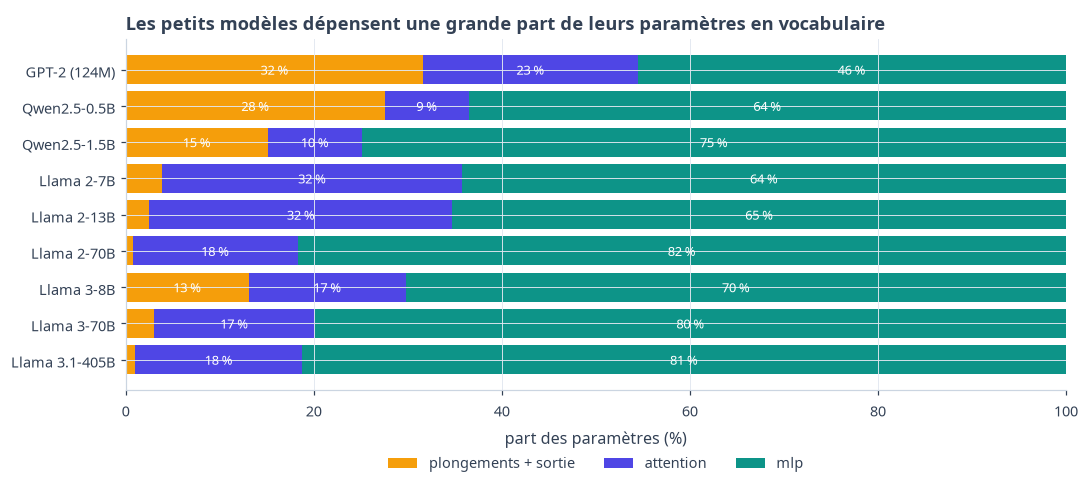

In [4]:
parts = {k: m.param_breakdown(m.KNOWN_CONFIGS[k]) for k in known}
dfp = pd.DataFrame(parts).T
total = dfp.sum(axis=1)
dfp["plongements + sortie"] = dfp["embeddings"] + dfp["positions"] + dfp["tête de sortie"]
frac = dfp[["plongements + sortie", "attention", "mlp"]].div(total, axis=0) * 100
fig, ax = plt.subplots(figsize=(10, 4.6))
left = np.zeros(len(frac))
for col, c in zip(frac.columns, [AMBER, INDIGO, TEAL]):
    ax.barh(frac.index, frac[col], left=left, color=c, label=col)
    for i, (l, v) in enumerate(zip(left, frac[col])):
        if v > 6:
            ax.text(l + v / 2, i, f"{v:.0f} %", ha="center", va="center", color="white", fontsize=8.5)
    left += frac[col].values
ax.invert_yaxis(); ax.set_xlabel("part des paramètres (%)"); ax.set_xlim(0, 100)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.14))
ax.set_title("Les petits modèles dépensent une grande part de leurs paramètres en vocabulaire")
plt.tight_layout(); plt.show()

Les plongements coûtent $Vd$ : un terme **linéaire** en $d$, alors que les blocs coûtent
$\approx 12 L d^2$, **quadratique**. Pour Qwen2.5-0.5B, avec un vocabulaire de 152 000
tokens, plus d'un quart des paramètres sert à la table des plongements (partagée avec la
sortie) ; pour Llama 3.1-405B, c'est moins de 1 %. C'est pourquoi les petits modèles
partagent souvent la matrice d'entrée et de sortie.

> **À retenir.** $N \approx L(4d^2 + 3d\,d_{ff}) + Vd$ (Llama/Qwen, sans GQA). Avec la
> configuration d'un modèle, on retrouve son nombre de paramètres à l'unité près, et on
> sait où ils se trouvent.

## 2. Mémoire : poids et cache KV

**Les poids.** Avec $b$ octets par paramètre, les poids occupent $N \cdot b$ octets :
un modèle de 7 milliards de paramètres en 16 bits demande au moins 14 Go pour
l'inférence (le chapitre 7 détaille le calcul complet, activations comprises, et la
quantification).

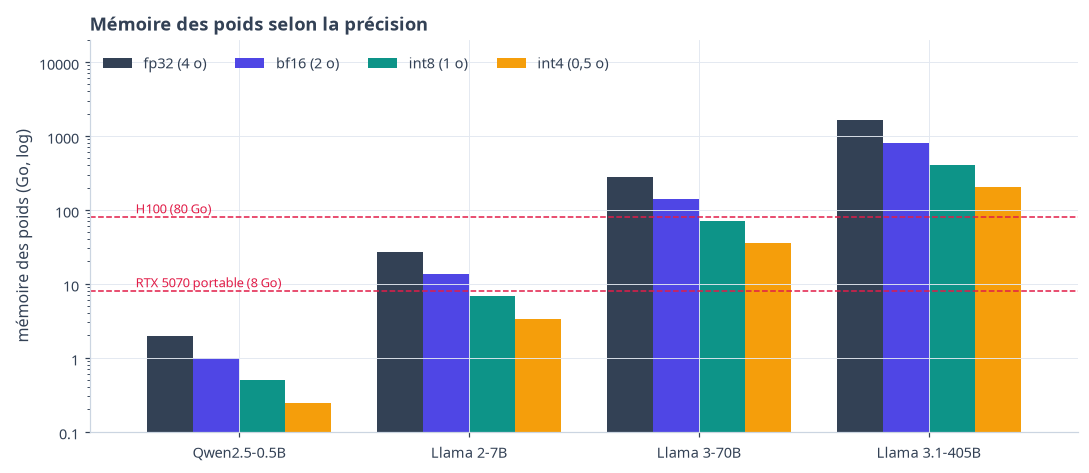

In [5]:
precisions = {"fp32 (4 o)": 4, "bf16 (2 o)": 2, "int8 (1 o)": 1, "int4 (0,5 o)": 0.5}
mods = ["Qwen2.5-0.5B", "Llama 2-7B", "Llama 3-70B", "Llama 3.1-405B"]
mem = pd.DataFrame({p: [m.weights_memory_gb(m.count_params_config(m.KNOWN_CONFIGS[k]), b) for k in mods]
                    for p, b in precisions.items()}, index=mods)
fig, ax = plt.subplots(figsize=(10, 4.4))
mem.plot.bar(ax=ax, color=[SLATE, INDIGO, TEAL, AMBER], width=0.8, rot=0)
ax.set_yscale("log"); m.plain_log_axis(ax, "y")
for gb, lab in [(8, "RTX 5070 portable (8 Go)"), (80, "H100 (80 Go)")]:
    ax.axhline(gb, color=ROSE, ls="--", lw=1); ax.text(-0.45, gb * 1.12, lab, color=ROSE, fontsize=8.5, ha="left")
ax.set_ylabel("mémoire des poids (Go, log)"); ax.set_xlabel("")
ax.set_title("Mémoire des poids selon la précision")
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, 1.0)); ax.set_ylim(0.1, 2e4)
plt.tight_layout(); plt.show()

**Le cache KV.** Pendant la génération, chaque token déjà traité laisse dans chaque
couche un vecteur clé et un vecteur valeur, conservés pour ne pas les recalculer (cours
1, section 6). Leur taille vaut
$$M_{KV} = 2 \times L \times h_{kv} \times d_h \times T \times B \times b \text{ octets}$$
pour $T$ tokens, un batch de $B$ séquences et $b$ octets par valeur. C'est pour cela que
le livre note qu'un contexte plus long n'ajoute aucun paramètre mais augmente l'empreinte
mémoire. Comparons Llama 2-7B (32 têtes KV), Llama 3-8B (GQA, 8 têtes KV) et Qwen2.5-0.5B.

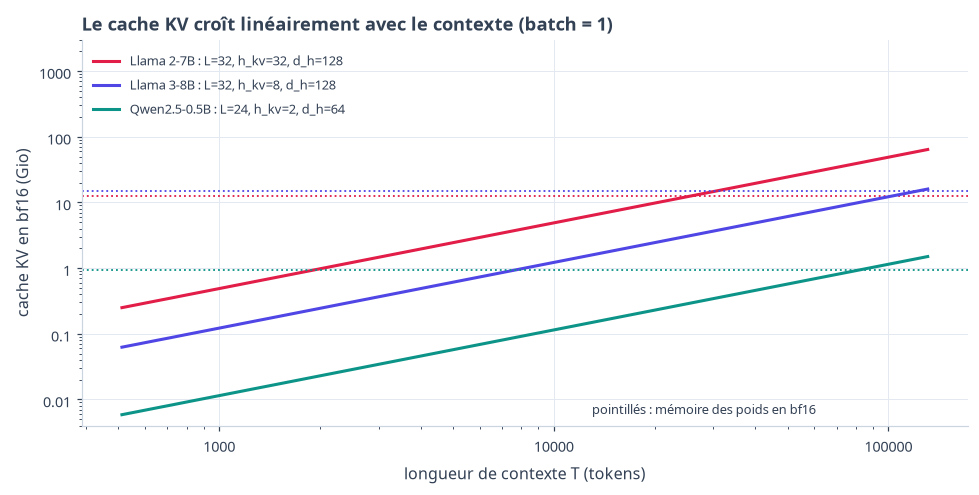

Llama 2-7B : cache KV à 4 096 tokens = 2.00 Gio, à 128 k tokens = 64 Gio
Llama 3-8B : cache KV à 4 096 tokens = 0.50 Gio, à 128 k tokens = 16 Gio


In [6]:
ctx = np.logspace(np.log10(512), np.log10(131072), 50)
fig, ax = plt.subplots(figsize=(9, 4.6))
for k, c in [("Llama 2-7B", ROSE), ("Llama 3-8B", INDIGO), ("Qwen2.5-0.5B", TEAL)]:
    cfg = m.KNOWN_CONFIGS[k]
    ax.loglog(ctx, [m.kv_cache_bytes(cfg, int(t)) / 2 ** 30 for t in ctx], color=c,
              label=f"{k} : L={cfg.n_layers}, h_kv={cfg.kv_heads}, d_h={cfg.head_dim}")
    w_gb = m.weights_memory_gb(m.count_params_config(cfg)) * 1e9 / 2 ** 30
    ax.axhline(w_gb, color=c, ls=":", lw=1.2)
ax.text(1.3e4, 0.006, "pointillés : mémoire des poids en bf16", fontsize=8.5, color=SLATE)
ax.set_xlabel("longueur de contexte T (tokens)"); ax.set_ylabel("cache KV en bf16 (Gio)")
m.plain_log_axis(ax); m.plain_log_axis(ax, "y")
ax.set_title("Le cache KV croît linéairement avec le contexte (batch = 1)")
ax.set_ylim(0.004, 3000)
ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout(); plt.show()
for k in ["Llama 2-7B", "Llama 3-8B"]:
    print(f"{k} : cache KV à 4 096 tokens = {m.kv_cache_bytes(m.KNOWN_CONFIGS[k], 4096) / 2**30:.2f} Gio, "
          f"à 128 k tokens = {m.kv_cache_bytes(m.KNOWN_CONFIGS[k], 131072) / 2**30:.0f} Gio")

À 128 000 tokens, le cache d'une seule conversation Llama 3-8B (16 Gio) dépasse déjà les
poids du modèle ; sans GQA, il serait quatre fois plus gros. Allonger le contexte d'un
transformer est donc d'abord un problème de **mémoire** (chapitres 7 et 9).

> **À retenir.** Poids : $N \cdot b$. Cache KV : $2 L h_{kv} d_h T B b$, proportionnel au
> contexte et au batch. La GQA (moins de têtes KV) est l'astuce standard pour le réduire.

## 3. Prefill et decode : deux régimes d'inférence

Le cours 1 l'a annoncé : un transformer traite l'**entrée en parallèle** (prefill) mais
**génère séquentiellement** (decode). Le schéma résume les deux phases.

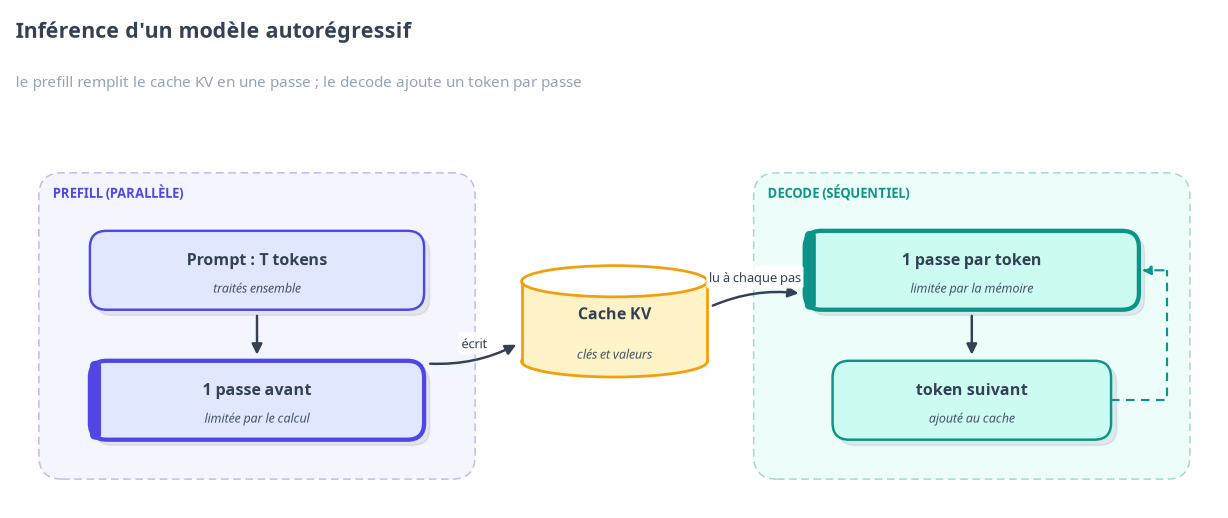

In [7]:
d = Diagram(13, 4.4, title="Inférence d'un modèle autorégressif",
            subtitle="le prefill remplit le cache KV en une passe ; le decode ajoute un token par passe")
d.group(0.3, 0.3, 5.0, 3.6, "prefill (parallèle)", color=INDIGO)
d.box("p", 2.65, 2.55, "Prompt : T tokens", sub="traités ensemble", color=INDIGO, w=3.6, h=0.85)
d.box("f1", 2.65, 1.15, "1 passe avant", sub="limitée par le calcul", color=INDIGO, kind="model", w=3.6, h=0.85)
d.arrow("p", "f1")
d.box("kv", 6.5, 2.0, "Cache KV", sub="clés et valeurs", color=AMBER, kind="db", w=2.0, h=1.2)
d.group(8.0, 0.3, 12.7, 3.6, "decode (séquentiel)", color=TEAL)
d.box("dec", 10.35, 2.55, "1 passe par token", sub="limitée par la mémoire", color=TEAL, kind="model", w=3.6,
      h=0.85)
d.box("tok", 10.35, 1.15, "token suivant", sub="ajouté au cache", color=TEAL, w=3.0, h=0.85)
d.arrow("f1", "kv", "écrit", rad=0.15)
d.arrow("kv", "dec", "lu à chaque pas", rad=-0.15)
d.arrow("dec", "tok")
d.line([(11.85, 1.15), (12.45, 1.15), (12.45, 2.55), (12.15, 2.55)], color=TEAL, style="dashed", lw=1.4)
d.show()

Mesurons-le sur Qwen2.5-0.5B : durée du prefill en fonction de la longueur du prompt, et
durée moyenne d'un pas de decode. Les temps absolus dépendent du matériel (et ici de la
charge du GPU, partagé avec d'autres travaux) ; c'est l'ordre de grandeur qui compte.

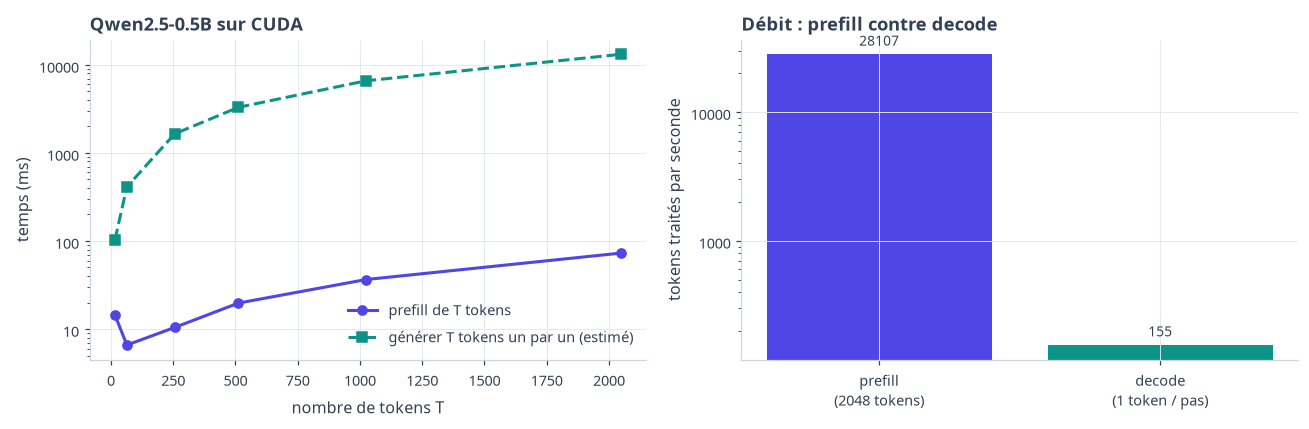

un pas de decode : 6.4 ms ; prefill de 2048 tokens : 73 ms


In [8]:
tok, model = llm.load(llm.SMALL)
dev = model.device


def sync():
    if dev.type == "cuda":
        torch.cuda.synchronize()


base_ids = torch.randint(1000, 20000, (1, 2048), generator=torch.Generator().manual_seed(0)).to(dev)
with torch.no_grad():
    model(base_ids[:, :32])  # échauffement
    prefill = []
    for T in [16, 64, 256, 512, 1024, 2048]:
        sync(); t0 = time.perf_counter()
        for _ in range(3):
            out = model(base_ids[:, :T], use_cache=True)
        sync(); prefill.append((T, (time.perf_counter() - t0) / 3))
    past = model(base_ids[:, :256], use_cache=True).past_key_values
    nxt = base_ids[:, 256:257]
    sync(); t0 = time.perf_counter()
    n_dec = 64
    for _ in range(n_dec):
        o = model(nxt, past_key_values=past, use_cache=True)
        past, nxt = o.past_key_values, o.logits[:, -1:].argmax(-1)
    sync(); t_dec = (time.perf_counter() - t0) / n_dec

pf = pd.DataFrame(prefill, columns=["T", "s"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.plot(pf["T"], pf["s"] * 1e3, "o-", color=INDIGO, label="prefill de T tokens")
ax.plot(pf["T"], pf["T"] * t_dec * 1e3, "s--", color=TEAL, label="générer T tokens un par un (estimé)")
ax.set_xlabel("nombre de tokens T"); ax.set_ylabel("temps (ms)"); ax.set_yscale("log")
m.plain_log_axis(ax, "y"); ax.legend(); ax.set_title(f"Qwen2.5-0.5B sur {dev.type.upper()}")
ax = axes[1]
ax.bar(["prefill\n(2048 tokens)", "decode\n(1 token / pas)"],
       [2048 / pf["s"].iloc[-1], 1 / t_dec], color=[INDIGO, TEAL])
annotate_bars(ax, "{:.0f}")
ax.set_ylabel("tokens traités par seconde"); ax.set_yscale("log"); m.plain_log_axis(ax, "y")
ax.set_title("Débit : prefill contre decode")
plt.tight_layout(); plt.show()
print(f"un pas de decode : {t_dec * 1e3:.1f} ms ; prefill de 2048 tokens : {pf['s'].iloc[-1] * 1e3:.0f} ms")

Traiter 2048 tokens d'un coup coûte à peine plus que quelques pas de decode : en prefill,
le GPU travaille sur de grosses matrices et exploite son parallélisme ; en decode, chaque
pas relit tous les poids (et le cache) pour ne produire qu'un token, si bien que la
vitesse est limitée par la **bande passante mémoire**. Conséquence pratique, souvent
reprise dans la tarification des API : les tokens de sortie sont plus chers et plus lents
que les tokens d'entrée.

> **À retenir.** Prefill : parallèle, débit élevé, conditionne le délai avant le premier
> token. Decode : séquentiel, un token par passe, conditionne la vitesse de génération.
> Le chapitre 9 exploite cette asymétrie pour optimiser l'inférence.

## 4. Au-delà du transformer (section *Other model architectures*)

Les architectures se succèdent en apprentissage profond ; le transformer, lui, domine
depuis 2017, ce que le livre qualifie de « collant » (*sticky*). Le remplacer est
difficile : il a été optimisé pendant des années pour le matériel actuel, et une
alternative doit faire ses preuves **à grande échelle**.

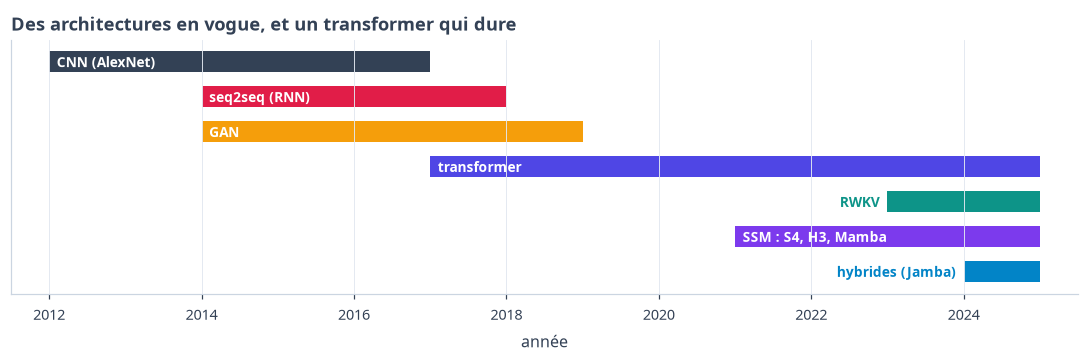

In [9]:
eras = [("CNN (AlexNet)", 2012, 2017, SLATE), ("seq2seq (RNN)", 2014, 2018, ROSE), ("GAN", 2014, 2019, AMBER),
        ("transformer", 2017, 2025, INDIGO), ("RWKV", 2023, 2025, TEAL), ("SSM : S4, H3, Mamba", 2021, 2025, VIOLET),
        ("hybrides (Jamba)", 2024, 2025, SKY)]
fig, ax = plt.subplots(figsize=(10, 3.4))
for i, (name, a, b, c) in enumerate(eras):
    ax.barh(i, b - a, left=a, color=c, height=0.6)
    if b - a >= 3:
        ax.text(a + 0.1, i, name, va="center", color="white", fontsize=9, fontweight="bold")
    else:
        ax.text(a - 0.1, i, name, va="center", ha="right", color=c, fontsize=9, fontweight="bold")
ax.set_yticks([]); ax.invert_yaxis(); ax.set_xlim(2011.5, 2025.5)
ax.set_xlabel("année"); ax.set_title("Des architectures en vogue, et un transformer qui dure")
plt.tight_layout(); plt.show()

Le talon d'Achille du transformer est la **longueur de séquence** : l'attention coûte
$O(T^2)$ en calcul pour le prefill, et chaque token généré doit relire un cache de taille
$O(T)$. Les **modèles à espace d'états** (SSM) reprennent l'idée des RNN avec un état de
taille fixe :
$$h_t = \bar A\, h_{t-1} + \bar B\, x_t, \qquad y_t = C\, h_t .$$
Leur atout : comme la récurrence est **linéaire**, la sortie s'écrit aussi comme une
**convolution** $y = K * x$ de noyau $K = (C\bar B, C\bar A\bar B, C\bar A^2\bar B, \dots)$,
calculable en parallèle pendant l'entraînement (S4), tandis que l'inférence utilise la
forme récurrente, à mémoire constante. Vérifions l'équivalence des deux formes en numpy.

écart max. entre forme récurrente et convolutive : 2.7e-15


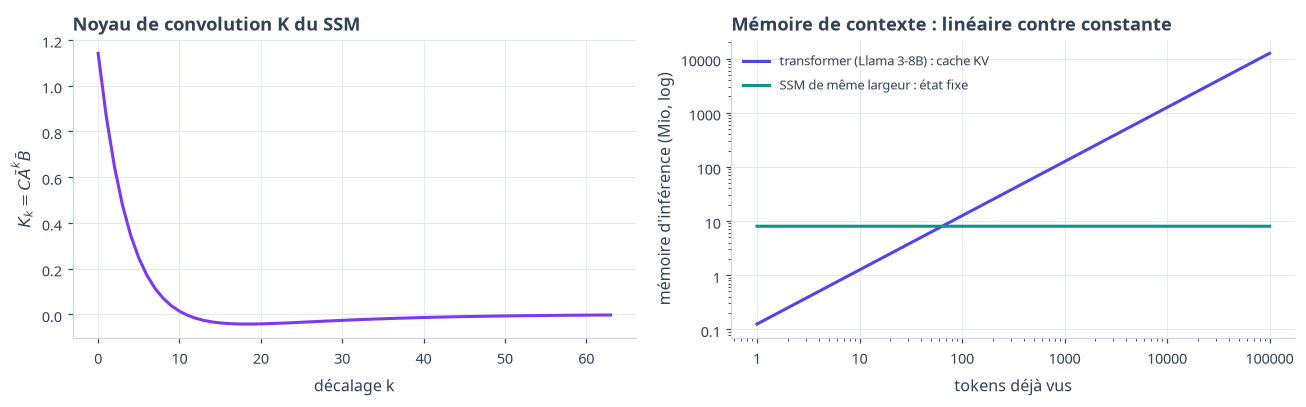

In [10]:
n_state, T_s = 8, 64
A = np.diag(rng.uniform(0.5, 0.97, n_state))   # dynamique stable (valeurs propres < 1)
B = rng.normal(size=(n_state, 1)); C = rng.normal(size=(1, n_state))
x_s = rng.normal(size=T_s)
# forme récurrente : un pas à la fois, état de taille fixe
h = np.zeros((n_state, 1)); y_rec = []
for t in range(T_s):
    h = A @ h + B * x_s[t]
    y_rec.append((C @ h).item())
# forme convolutive : noyau K_k = C A^k B, puis y_t = sum_k K_k x_{t-k}
Kc = np.array([(C @ np.linalg.matrix_power(A, k) @ B).item() for k in range(T_s)])
y_conv = np.array([sum(Kc[k] * x_s[t - k] for k in range(t + 1)) for t in range(T_s)])
print(f"écart max. entre forme récurrente et convolutive : {np.abs(np.array(y_rec) - y_conv).max():.1e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(Kc, color=VIOLET); axes[0].set_title("Noyau de convolution K du SSM")
axes[0].set_xlabel("décalage k"); axes[0].set_ylabel(r"$K_k = C\bar A^k \bar B$")
Tg = np.arange(1, 100_001)
cfg8 = m.KNOWN_CONFIGS["Llama 3-8B"]
axes[1].loglog(Tg, Tg * m.kv_cache_bytes(cfg8, 1) / 2 ** 20, color=INDIGO,
               label="transformer (Llama 3-8B) : cache KV")
ssm_state = cfg8.n_layers * 2 * cfg8.d_model * 16 * 2  # ordre de grandeur Mamba : L x (2d) x N=16 x 2 octets
axes[1].loglog(Tg, np.full_like(Tg, ssm_state / 2 ** 20, dtype=float), color=TEAL,
               label="SSM de même largeur : état fixe")
axes[1].set_xlabel("tokens déjà vus"); axes[1].set_ylabel("mémoire d'inférence (Mio, log)")
m.plain_log_axis(axes[1]); m.plain_log_axis(axes[1], "y")
axes[1].set_title("Mémoire de contexte : linéaire contre constante"); axes[1].legend(fontsize=8.5)
plt.tight_layout(); plt.show()

Le livre retrace l'évolution de cette famille : **S4** (2021) rend les SSM efficaces,
**H3** (2022) ajoute un mécanisme de rappel proche de l'attention, **Mamba** (2023) rend
les paramètres $\bar A, \bar B, C$ dépendants de l'entrée (sélectivité) et atteint, à
3 milliards de paramètres, la qualité de transformers deux fois plus gros avec un coût
linéaire en $T$ ; **Jamba** (2024) entrelace couches transformer et Mamba avec un mélange
d'experts (52 milliards de paramètres dont 12 actifs, contexte de 256 000 tokens sur un
seul GPU de 80 Go). **RWKV** est un RNN parallélisable à l'entraînement. Rien ne garantit
toutefois qu'une architecture sans limite théorique de contexte exploite bien un long
contexte en pratique.

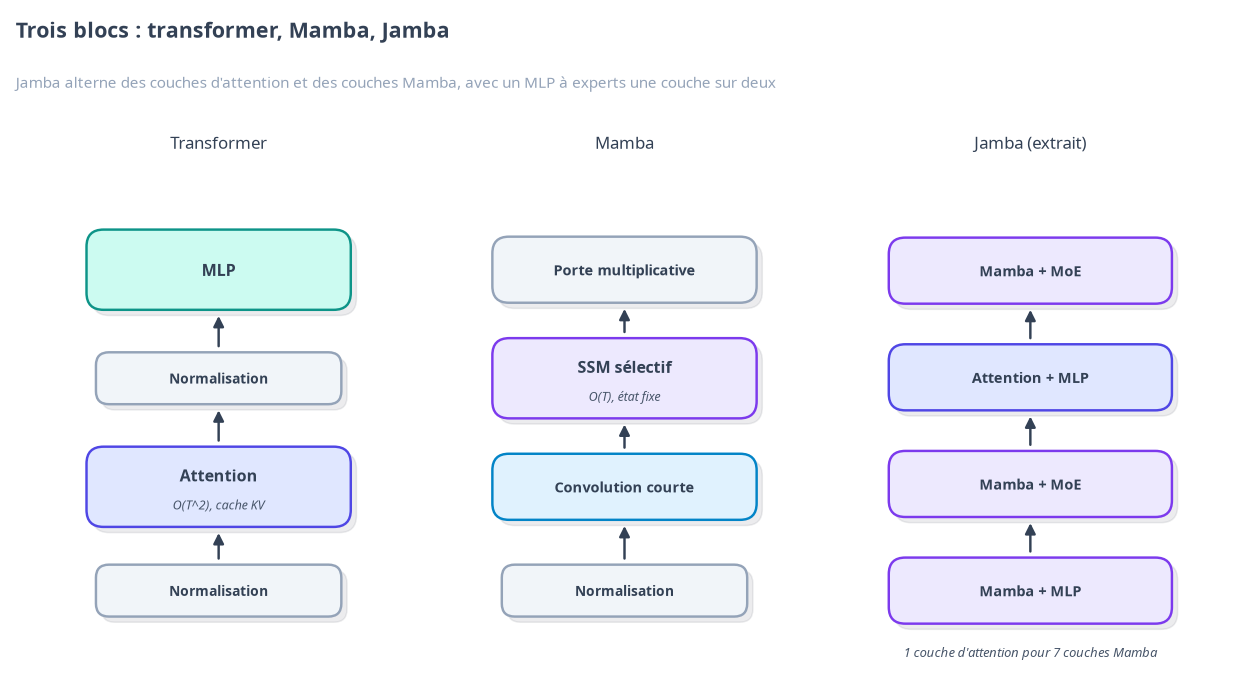

In [11]:
d = Diagram(13, 6.2, title="Trois blocs : transformer, Mamba, Jamba",
            subtitle="Jamba alterne des couches d'attention et des couches Mamba, avec un MLP à experts une couche sur deux")
cols = [(2.2, "Transformer"), (6.5, "Mamba"), (10.8, "Jamba (extrait)")]
for x, name in cols:
    d.note(x, 5.75, name, color=SLATE, fontsize=11, style="normal")
# transformer
d.box("tn1", 2.2, 1.0, "Normalisation", color=GRAY, w=2.6, h=0.55, fontsize=9)
d.box("ta", 2.2, 2.1, "Attention", sub="O(T^2), cache KV", color=INDIGO, w=2.8, h=0.85)
d.box("tn2", 2.2, 3.25, "Normalisation", color=GRAY, w=2.6, h=0.55, fontsize=9)
d.box("tm", 2.2, 4.4, "MLP", color=TEAL, w=2.8, h=0.85)
for a, b in [("tn1", "ta"), ("ta", "tn2"), ("tn2", "tm")]:
    d.arrow(a, b)
# mamba
d.box("mn", 6.5, 1.0, "Normalisation", color=GRAY, w=2.6, h=0.55, fontsize=9)
d.box("mc", 6.5, 2.1, "Convolution courte", color=SKY, w=2.8, h=0.7, fontsize=9.5)
d.box("ms", 6.5, 3.25, "SSM sélectif", sub="O(T), état fixe", color=VIOLET, w=2.8, h=0.85)
d.box("mg", 6.5, 4.4, "Porte multiplicative", color=GRAY, w=2.8, h=0.7, fontsize=9.5)
for a, b in [("mn", "mc"), ("mc", "ms"), ("ms", "mg")]:
    d.arrow(a, b)
# jamba
labels_j = [("j1", "Mamba + MLP", VIOLET), ("j2", "Mamba + MoE", VIOLET), ("j3", "Attention + MLP", INDIGO),
            ("j4", "Mamba + MoE", VIOLET)]
for i, (nm, txt, c) in enumerate(labels_j):
    d.box(nm, 10.8, 1.0 + 1.13 * i, txt, color=c, w=3.0, h=0.7, fontsize=9.5)
for i in range(3):
    d.arrow(labels_j[i][0], labels_j[i + 1][0])
d.note(10.8, 0.35, "1 couche d'attention pour 7 couches Mamba", fontsize=8.5)
d.show()

> **À retenir.** Les SSM (Mamba) et les RNN parallélisables (RWKV) offrent une inférence
> à mémoire constante et un coût linéaire en longueur, là où le transformer est
> quadratique. Les hybrides comme Jamba combinent les deux. Changer d'architecture
> modifierait certaines techniques d'adaptation, pas les principes de l'ingénierie IA.

## 5. Parcimonie et mélange d'experts (section *Model Size*)

Plus de paramètres signifie en général plus de capacité d'apprentissage : à famille
égale, un 13B surpasse un 7B. Mais le nombre de paramètres peut tromper :

- un modèle **parcimonieux** (*sparse*) à 90 % de zéros n'a que 10 % de paramètres utiles
  (700 millions pour un 7B) ;
- un **mélange d'experts** (MoE) n'active qu'une partie de ses paramètres par token. Dans
  Mixtral 8x7B, chaque couche possède 8 MLP « experts » et un **routeur** qui en choisit
  2 par token. Huit fois 7 milliards ferait 56 milliards, mais l'attention et les
  plongements sont partagés : le modèle compte 46,7 milliards de paramètres, dont
  12,9 milliards actifs par token. Coût et vitesse sont ceux d'un modèle de 12,9 milliards
  (la mémoire, elle, doit contenir les 46,7 milliards).

Notre fonction de comptage retrouve ces chiffres à partir de la configuration de Mixtral :

Mixtral 8x7B : 46.7 G paramètres au total, 12.9 G actifs par token


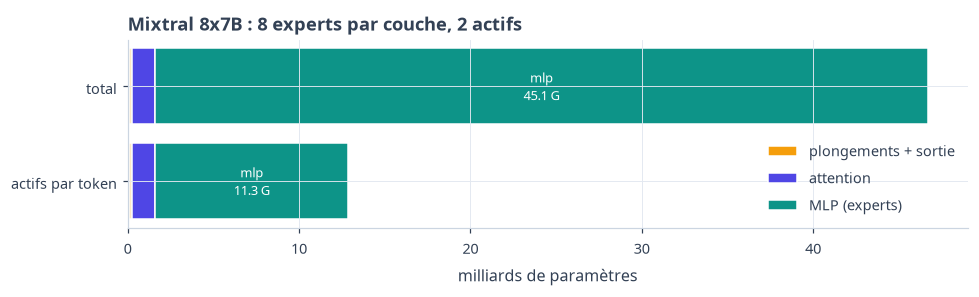

In [12]:
mix = m.KNOWN_CONFIGS["Mixtral 8x7B"]
bd_total, bd_active = m.param_breakdown(mix), m.param_breakdown(mix, active=True)
print(f"Mixtral 8x7B : {m.count_params_config(mix) / 1e9:.1f} G paramètres au total, "
      f"{m.count_params_config(mix, active=True) / 1e9:.1f} G actifs par token")
fig, ax = plt.subplots(figsize=(9, 2.8))
for i, (lab, bd) in enumerate([("total", bd_total), ("actifs par token", bd_active)]):
    left = 0
    for comp, c, leg in [("embeddings", AMBER, "plongements + sortie"), ("tête de sortie", AMBER, None),
                         ("attention", INDIGO, "attention"), ("mlp", TEAL, "MLP (experts)")]:
        ax.barh(i, bd[comp] / 1e9, left=left, color=c, edgecolor="white", label=leg if i == 0 else None)
        if bd[comp] / 1e9 > 2:
            ax.text(left + bd[comp] / 2e9, i, f"{comp}\n{bd[comp] / 1e9:.1f} G", ha="center", va="center",
                    color="white", fontsize=8.5)
        left += bd[comp] / 1e9
ax.set_yticks([0, 1], ["total", "actifs par token"]); ax.invert_yaxis()
ax.set_xlabel("milliards de paramètres"); ax.set_title("Mixtral 8x7B : 8 experts par couche, 2 actifs")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

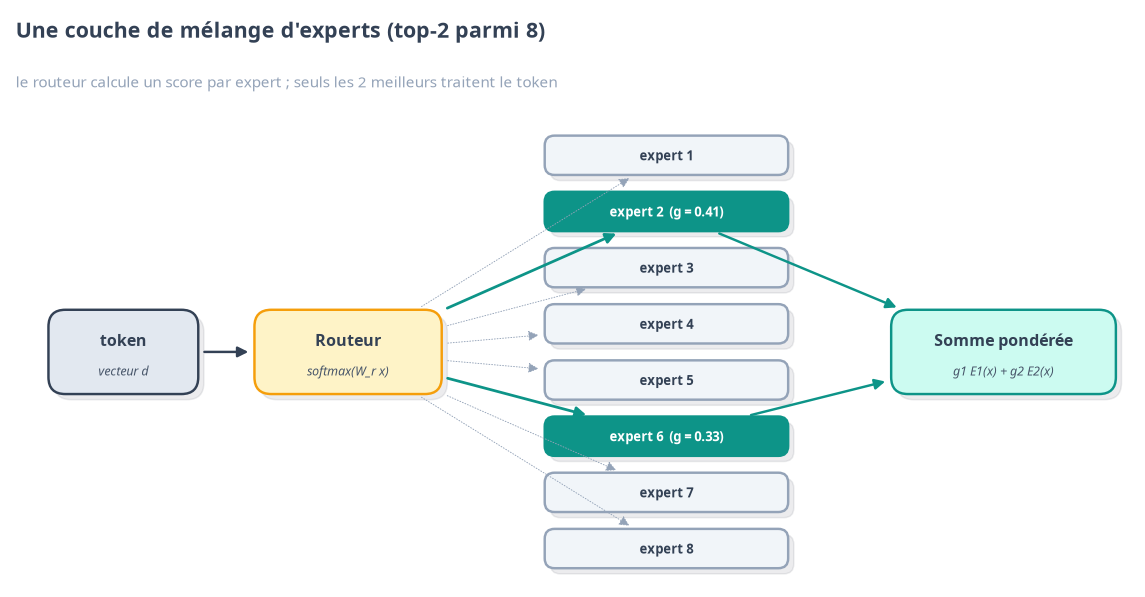

In [13]:
d = Diagram(12, 5.2, title="Une couche de mélange d'experts (top-2 parmi 8)",
            subtitle="le routeur calcule un score par expert ; seuls les 2 meilleurs traitent le token")
d.box("x", 1.2, 2.5, "token", sub="vecteur d", color=SLATE, w=1.6, h=0.9)
d.box("r", 3.6, 2.5, "Routeur", sub="softmax(W_r x)", color=AMBER, w=2.0, h=0.9)
d.arrow("x", "r")
gates = [0.05, 0.41, 0.03, 0.08, 0.02, 0.33, 0.04, 0.04]
for i, g in enumerate(gates):
    y = 4.6 - i * 0.6
    active = g > 0.3
    d.box(f"e{i}", 7.0, y, f"expert {i + 1}" + (f"  (g = {g:.2f})" if active else ""), color=TEAL if active else GRAY,
          w=2.6, h=0.42, fontsize=8.5, filled=active)
    d.arrow("r", f"e{i}", color=TEAL if active else GRAY, lw=1.8 if active else 0.6,
            style="solid" if active else "dotted")
d.box("s", 10.6, 2.5, "Somme pondérée", sub="g1 E1(x) + g2 E2(x)", color=TEAL, w=2.4, h=0.9)
d.arrow("e1", "s", color=TEAL); d.arrow("e5", "s", color=TEAL)
d.show()

> **À retenir.** Distinguez paramètres **totaux** (mémoire) et paramètres **actifs**
> (calcul et latence). Un MoE offre la capacité d'un gros modèle au coût de calcul d'un
> petit, au prix d'une mémoire importante.

## 6. Tokens, FLOPs et dollars

**Mesurer les données.** Le nombre d'exemples ne veut rien dire pour un modèle de
langue (une phrase et un livre comptent chacun pour un) : on compte les **tokens**.
Meta est passé de 1,4 (Llama 1) à 2 (Llama 2) puis 15 000 milliards de tokens (Llama 3).
Le jeu RedPajama-v2 contient 30 000 milliards de tokens, soit, à 67 000 tokens par livre,
environ $30 \cdot 10^{12} / 67\,000 \approx 450$ millions de livres. On distingue la taille
du jeu de données et le nombre de **tokens d'entraînement** (un jeu de 1 000 milliards
de tokens vu deux fois, deux **époques**, donne 2 000 milliards de tokens d'entraînement ;
les grands modèles sont généralement pré-entraînés sur une seule époque).

**Mesurer le calcul : la règle $C \approx 6ND$.** Pour un modèle dense de $N$ paramètres
entraîné sur $D$ tokens :

- **passe avant** : chaque paramètre intervient dans une multiplication et une addition
  par token, soit environ $2N$ FLOPs par token ;
- **rétropropagation** : il faut calculer le gradient par rapport aux activations **et**
  par rapport aux poids, soit environ deux fois la passe avant, $4N$ FLOPs par token.

D'où $C \approx 6ND$ FLOPs (on néglige le terme d'attention en $T^2$, faible tant que le
contexte est modeste devant $d$). Pour GPT-3 : $6 \times 175\cdot 10^9 \times 300 \cdot
10^9 = 3{,}15 \cdot 10^{23}$ FLOPs, très proche des $3{,}14 \cdot 10^{23}$ publiés.

**Attention aux notations.** Les FLOPs comptent des opérations ; les FLOP/s mesurent la
vitesse d'une machine. Le livre retient 60 TFLOP/s pour une H100, soit
$6\cdot 10^{13} \times 86\,400 \approx 5{,}2 \cdot 10^{18}$ FLOPs par jour.

In [14]:
C_gpt3 = 3.14e23
peak = 60e12
for util in [1.0, 0.7, 0.5]:
    days = m.training_days(C_gpt3, 256, peak, util)
    cost = m.training_cost(C_gpt3, peak, 2.0, util)
    print(f"GPT-3 sur 256 H100, utilisation {util:.0%} : {days:5.0f} jours, {cost / 1e6:4.1f} M$ à 2 $/h")

GPT-3 sur 256 H100, utilisation 100% :   237 jours,  2.9 M$ à 2 $/h
GPT-3 sur 256 H100, utilisation 70% :   338 jours,  4.2 M$ à 2 $/h
GPT-3 sur 256 H100, utilisation 50% :   473 jours,  5.8 M$ à 2 $/h


À pleine utilisation, on retrouve les ~236 jours du livre ; à 70 % d'utilisation (déjà
« excellent »), plus de 4 millions de dollars (le livre aboutit au même montant ; son
calcul utilise bien les 236 jours). L'**utilisation** (part de la puissance de crête
réellement exploitée) est un levier de coût aussi important que le prix du GPU.

Appliquons la règle $6ND$ à quelques modèles connus :

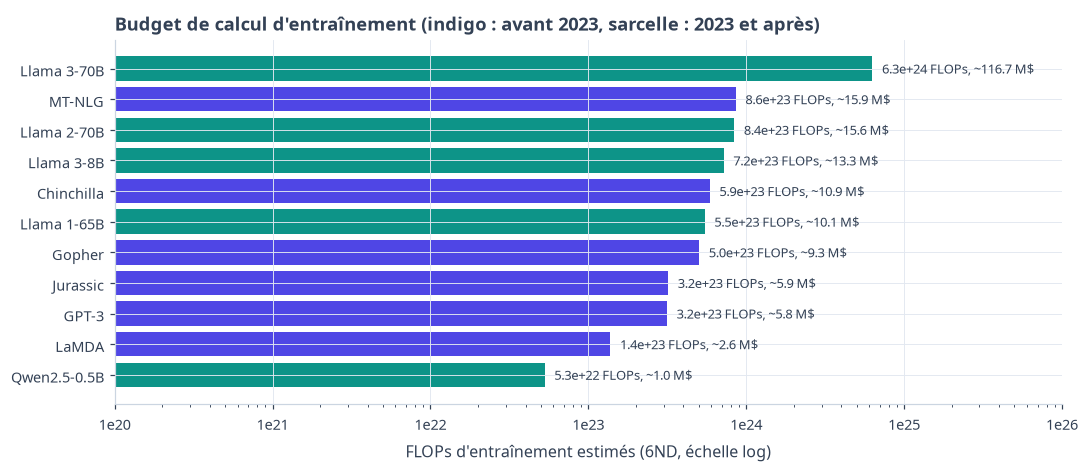

In [15]:
ms = pd.DataFrame(m.MODELS_SCALE, columns=["modèle", "année", "N", "D"])
ms["FLOPs"] = m.training_flops(ms.N, ms.D)
ms["jours (1 000 H100, 50 %)"] = m.training_days(ms.FLOPs, 1000, peak, 0.5)
ms["coût (M$, 2 $/h, 50 %)"] = m.training_cost(ms.FLOPs, peak, 2.0, 0.5) / 1e6
fig, ax = plt.subplots(figsize=(10, 4.4))
srt = ms.sort_values("FLOPs")
bars = ax.barh(srt["modèle"], srt["FLOPs"], color=[INDIGO if y < 2023 else TEAL for y in srt["année"]])
ax.set_xscale("log"); m.plain_log_axis(ax, fmt=sci)
for b, (_, r) in zip(bars, srt.iterrows()):
    ax.text(b.get_width() * 1.15, b.get_y() + b.get_height() / 2,
            f"{r.FLOPs:.1e} FLOPs, ~{r['coût (M$, 2 $/h, 50 %)']:.1f} M$", va="center", fontsize=8.5)
ax.set_xlim(1e20, 1e26); ax.set_xlabel("FLOPs d'entraînement estimés (6ND, échelle log)")
ax.set_title("Budget de calcul d'entraînement (indigo : avant 2023, sarcelle : 2023 et après)")
plt.tight_layout(); plt.show()

Le livre résume l'échelle d'un modèle par trois nombres : **paramètres** (capacité
d'apprentissage), **tokens d'entraînement** (ce qu'il a appris) et **FLOPs** (coût
d'entraînement). Notez Qwen2.5-0.5B : petit en paramètres, mais entraîné sur 18 000
milliards de tokens, il a consommé un budget ($5 \cdot 10^{22}$ FLOPs) pour lequel la règle
de Chinchilla (section suivante) recommanderait un modèle d'environ 20 milliards de
paramètres.

**Une mise en garde du livre : l'*inverse scaling*.** Plus gros n'est pas toujours
mieux : le concours *Inverse Scaling Prize* (2023) a trouvé des tâches (mémorisation,
tâches à fort a priori) où les grands modèles font moins bien, sans démontrer d'échec
dans le monde réel.

> **À retenir.** $C \approx 6ND$. Durée $= C / (n_{GPU} \times \text{débit crête} \times
> \text{utilisation})$, coût = heures-GPU $\times$ prix. Ces trois lignes suffisent pour
> estimer le budget de n'importe quel pré-entraînement.

## 7. La loi de Chinchilla (section *Scaling law: Building compute-optimal models*)

On part d'un **budget** de calcul $C$ fixé. Faut-il un gros modèle peu entraîné ou un
petit modèle très entraîné ? Hoffmann et al. (2022, l'article « Chinchilla ») ont
entraîné plus de 400 modèles (de 70 millions à 16 milliards de paramètres, sur 5 à 500
milliards de tokens) et ajusté la perte finale par
$$L(N, D) = E + \frac{A}{N^{\alpha}} + \frac{B}{D^{\beta}},\qquad
E = 1{,}69,\ A = 406{,}4,\ B = 410{,}7,\ \alpha = 0{,}34,\ \beta = 0{,}28 .$$
$E$ est l'entropie irréductible du texte ; les deux autres termes sont les pénalités
d'un modèle trop petit et de données trop peu nombreuses. Minimiser $L$ sous la
contrainte $6ND = C$ donne (en annulant la dérivée en $N$ de $L(N, C/6N)$) :
$$N^\star = G\,\Big(\frac{C}{6}\Big)^{\frac{\beta}{\alpha+\beta}},\quad
D^\star = \frac{C}{6N^\star},\quad G = \Big(\frac{\alpha A}{\beta B}\Big)^{\frac{1}{\alpha+\beta}} .$$
La règle pratique retenue par le livre est plus simple : **environ 20 tokens par
paramètre**, et doubler $D$ chaque fois que l'on double $N$.

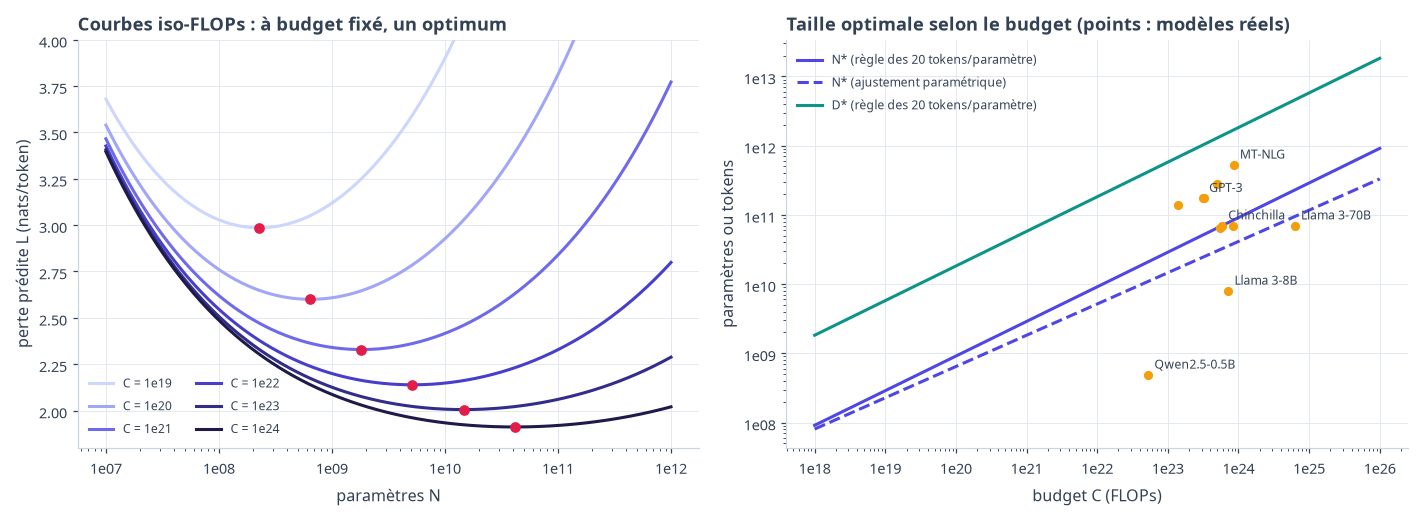

In [16]:
budgets = [1e19, 1e20, 1e21, 1e22, 1e23, 1e24]
Ngrid = np.logspace(7, 12, 400)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
cmap = plt.get_cmap("aie_seq")
for i, C in enumerate(budgets):
    loss = m.chinchilla_loss(Ngrid, C / (6 * Ngrid))
    c = cmap(0.3 + 0.7 * i / (len(budgets) - 1))
    ax.semilogx(Ngrid, loss, color=c, label=f"C = {sci(C)}")
    No, Do = m.chinchilla_optimal(C, "parametric")
    ax.plot(No, m.chinchilla_loss(No, Do), "o", color=ROSE, ms=6, zorder=3)
ax.set_ylim(1.8, 4.0); ax.set_xlabel("paramètres N"); ax.set_ylabel("perte prédite L (nats/token)")
ax.set_title("Courbes iso-FLOPs : à budget fixé, un optimum")
m.plain_log_axis(ax, fmt=sci); ax.legend(fontsize=8, ncol=2)
ax = axes[1]
Cs = np.logspace(18, 26, 50)
N_par = np.array([m.chinchilla_optimal(C, "parametric")[0] for C in Cs])
N_20 = np.array([m.chinchilla_optimal(C)[0] for C in Cs])
ax.loglog(Cs, N_20, color=INDIGO, label="N* (règle des 20 tokens/paramètre)")
ax.loglog(Cs, N_par, color=INDIGO, ls="--", label="N* (ajustement paramétrique)")
ax.loglog(Cs, 20 * N_20, color=TEAL, label="D* (règle des 20 tokens/paramètre)")
for _, r in ms.iterrows():
    ax.plot(r.FLOPs, r.N, "o", color=AMBER, ms=5)
    if r.modèle in ("GPT-3", "Chinchilla", "Llama 3-8B", "Qwen2.5-0.5B", "MT-NLG", "Llama 3-70B"):
        ax.annotate(r.modèle, (r.FLOPs, r.N), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("budget C (FLOPs)"); ax.set_ylabel("paramètres ou tokens")
m.plain_log_axis(ax, fmt=sci); m.plain_log_axis(ax, "y", sci)
ax.set_title("Taille optimale selon le budget (points : modèles réels)"); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

Les points rouges (minima) dessinent la **frontière compute-optimale**. Sur la figure de
droite, les modèles de 2020-2022 (GPT-3, MT-NLG) sont **au-dessus** de la droite :
trop de paramètres pour leurs données. Chinchilla (70 G paramètres, 1 400 G tokens) a
battu Gopher (280 G) avec le même budget en rééquilibrant. À l'inverse, Llama 3 et
Qwen2.5 sont très **en dessous** : volontairement « sur-entraînés ». Les deux variantes
de la loi (règle des 20 et ajustement paramétrique) divergent aux grands budgets, ce qui
rappelle qu'il s'agit d'ajustements empiriques.

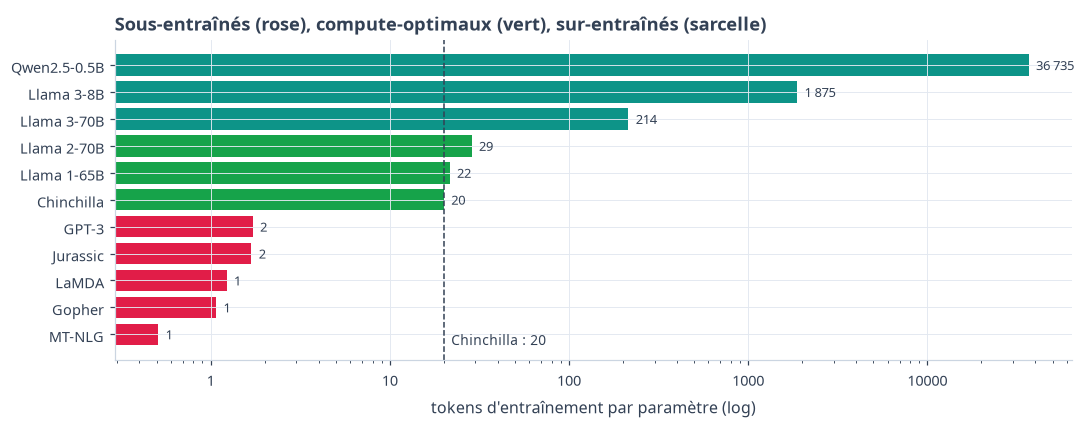

In [17]:
ratio = ms.assign(tokens_par_param=ms.D / ms.N).sort_values("tokens_par_param")
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(ratio["modèle"], ratio["tokens_par_param"],
        color=[ROSE if r < 10 else (GREEN if r < 40 else TEAL) for r in ratio["tokens_par_param"]])
ax.axvline(20, color=SLATE, ls="--", lw=1); ax.text(22, -0.4, "Chinchilla : 20", fontsize=9)
ax.set_xscale("log"); m.plain_log_axis(ax)
for i, v in enumerate(ratio["tokens_par_param"]):
    ax.text(v * 1.1, i, f"{v:,.0f}".replace(",", " "), va="center", fontsize=8.5)
ax.set_xlabel("tokens d'entraînement par paramètre (log)")
ax.set_title("Sous-entraînés (rose), compute-optimaux (vert), sur-entraînés (sarcelle)")
plt.tight_layout(); plt.show()

**Pourquoi sur-entraîner ?** Chinchilla optimise la qualité pour un budget
d'**entraînement**. Mais un modèle déployé sert des milliards de requêtes : son coût
d'**inférence** ($\approx 2N$ FLOPs par token généré) finit par dominer. Sardana et al.
(2023) ajoutent ce terme : pour atteindre une perte cible $L^\star$ en servant
$D_{\text{inf}}$ tokens, on minimise
$$C_{\text{total}}(N) = 6\,N\,D(N) + 2\,N\,D_{\text{inf}},$$
où $D(N)$ est le nombre de tokens nécessaire pour atteindre $L^\star$ avec $N$
paramètres (obtenu en inversant la loi de Hoffmann).

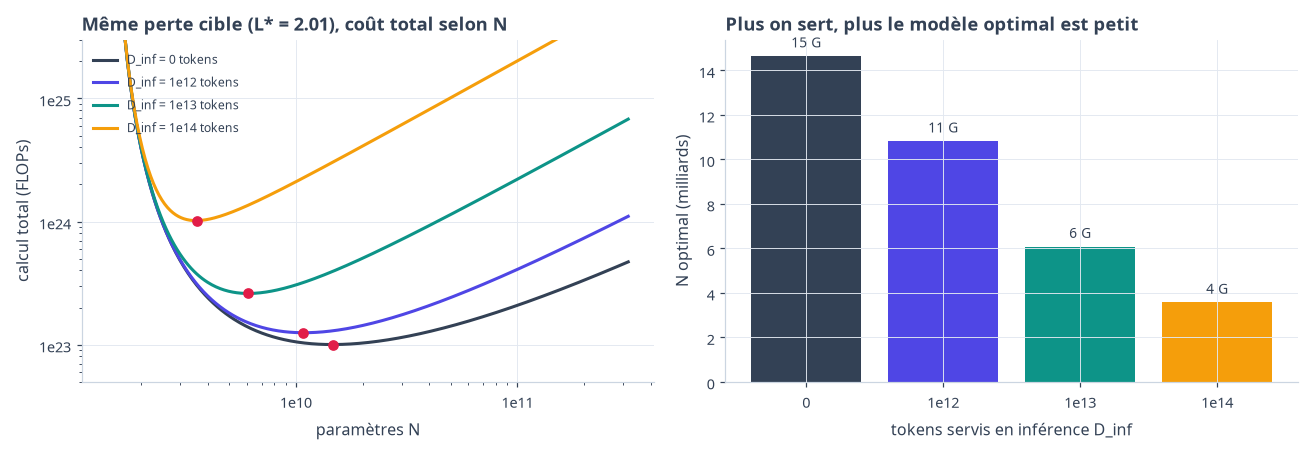

In [18]:
E, A_, B_, a_, b_ = (m.CHINCHILLA[k] for k in ["E", "A", "B", "alpha", "beta"])
N0, D0 = m.chinchilla_optimal(1e23, "parametric")
L_star = float(m.chinchilla_loss(N0, D0))  # perte d'un modèle Chinchilla-optimal à 1e23 FLOPs
Ns = np.logspace(9, 11.5, 400)
gap = L_star - E - A_ / Ns ** a_
valid = gap > 0
D_needed = np.where(valid, (B_ / np.where(valid, gap, 1)) ** (1 / b_), np.nan)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
opt_N = []
dinfs = [0, 1e12, 1e13, 1e14]
for D_inf, c in zip(dinfs, [SLATE, INDIGO, TEAL, AMBER]):
    tot = 6 * Ns * D_needed + 2 * Ns * D_inf
    axes[0].loglog(Ns, tot, color=c, label=f"D_inf = {sci(D_inf) if D_inf else '0'} tokens")
    j = np.nanargmin(tot); opt_N.append(Ns[j])
    axes[0].plot(Ns[j], tot[j], "o", color=ROSE)
axes[0].set_xlabel("paramètres N"); axes[0].set_ylabel("calcul total (FLOPs)"); axes[0].set_ylim(5e22, 3e25)
axes[0].set_title(f"Même perte cible (L* = {L_star:.2f}), coût total selon N"); axes[0].legend(fontsize=8)
m.plain_log_axis(axes[0], fmt=sci); m.plain_log_axis(axes[0], "y", sci)
axes[1].bar([sci(x) if x else "0" for x in dinfs], np.array(opt_N) / 1e9, color=[SLATE, INDIGO, TEAL, AMBER])
annotate_bars(axes[1], "{:.0f} G")
axes[1].set_xlabel("tokens servis en inférence D_inf"); axes[1].set_ylabel("N optimal (milliards)")
axes[1].set_title("Plus on sert, plus le modèle optimal est petit")
plt.tight_layout(); plt.show()

Quand la demande d'inférence est forte, l'optimum glisse vers des modèles **plus
petits, entraînés plus longtemps**. C'est exactement le choix de Llama (le livre note
que ses auteurs auraient pu viser plus gros pour le même budget, mais ont privilégié des
modèles faciles et peu coûteux à servir), et celui de Qwen2.5-0.5B.

Deux autres remarques du livre : le coût pour **atteindre** une performance donnée
baisse avec le temps (meilleur matériel, meilleurs algorithmes), mais le coût pour
**améliorer** reste élevé, car les gains sont des lois de puissance : passer de 3 % à
2 % d'erreur peut demander dix fois plus de données ou de calcul.

> **À retenir.** À budget d'entraînement fixé, il existe une taille optimale
> (Chinchilla : ~20 tokens par paramètre). En production, le coût d'inférence pousse vers
> des modèles plus petits et sur-entraînés : la qualité n'est pas le seul critère.

## 8. Extrapolation et capacités émergentes (section *Scaling extrapolation*)

Un **paramètre** est appris pendant l'entraînement ; un **hyperparamètre** est fixé par
l'utilisateur (nombre de couches, dimension, vocabulaire, taille de batch, taux
d'apprentissage...). Pour un grand modèle, on n'a souvent **qu'un essai** : impossible de
tester $2^{10} = 1024$ combinaisons de 10 hyperparamètres binaires. On étudie donc de
petits modèles et l'on **extrapole** (le livre cite un transfert d'hyperparamètres d'un
modèle de 40 millions à 6,7 milliards de paramètres).

Simulons cette démarche : on « entraîne » 12 petits modèles (budgets de $10^{17}$ à
$10^{19}$ FLOPs, pertes tirées de la loi de Hoffmann plus un bruit de mesure), on ajuste
une loi de puissance $L(C) = E + k\,C^{-\gamma}$, puis on extrapole jusqu'à $10^{24}$.

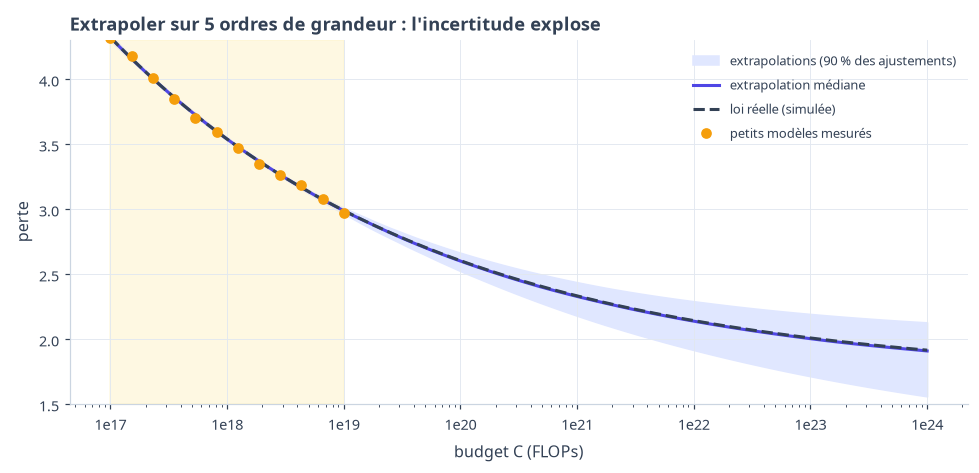

In [19]:
from scipy.optimize import curve_fit

C_small = np.logspace(17, 19, 12)
L_true = np.array([float(m.chinchilla_loss(*m.chinchilla_optimal(C, "parametric"))) for C in C_small])
law = lambda c, e, k, g: e + k * (c / 1e17) ** (-g)
C_big = np.logspace(17, 24, 100)
L_big_true = np.array([float(m.chinchilla_loss(*m.chinchilla_optimal(C, "parametric"))) for C in C_big])
preds = []
rb = np.random.default_rng(1)
for _ in range(200):  # rééchantillonnage du bruit de mesure
    L_obs = L_true + rb.normal(0, 0.02, L_true.size)
    try:
        p, _ = curve_fit(law, C_small, L_obs, p0=[1.7, 1.0, 0.1], maxfev=20000)
        preds.append(law(C_big, *p))
    except RuntimeError:
        pass
preds = np.array(preds)
lo, med, hi = np.percentile(preds, [5, 50, 95], axis=0)
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.fill_between(C_big, lo, hi, color=LIGHT[INDIGO], label="extrapolations (90 % des ajustements)")
ax.semilogx(C_big, med, color=INDIGO, label="extrapolation médiane")
ax.semilogx(C_big, L_big_true, color=SLATE, ls="--", label="loi réelle (simulée)")
ax.plot(C_small, L_true + rb.normal(0, 0.02, L_true.size), "o", color=AMBER, label="petits modèles mesurés")
ax.axvspan(1e17, 1e19, color=LIGHT[AMBER], alpha=0.5)
ax.set_xlabel("budget C (FLOPs)"); ax.set_ylabel("perte"); m.plain_log_axis(ax, fmt=sci)
ax.set_ylim(1.5, 4.3)
ax.set_title("Extrapoler sur 5 ordres de grandeur : l'incertitude explose"); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

Avec un bruit de mesure de seulement 0,02 nat, la fourchette des extrapolations à
$10^{24}$ FLOPs est large : de petites erreurs sur l'exposant $\gamma$ se paient très cher
à grande distance.

**Capacités émergentes.** Le livre ajoute que certaines capacités n'apparaissent qu'à
grande échelle (Wei et al., 2022), ce qui rend l'extrapolation encore moins fiable. Une
explication partielle, discutée dans la littérature (Schaeffer et al., 2023), tient à la
**métrique** : si la probabilité $p$ de produire correctement chaque token progresse
doucement avec l'échelle, l'exactitude d'une réponse de $k$ tokens, $p^k$, peut sembler
« surgir » brutalement.

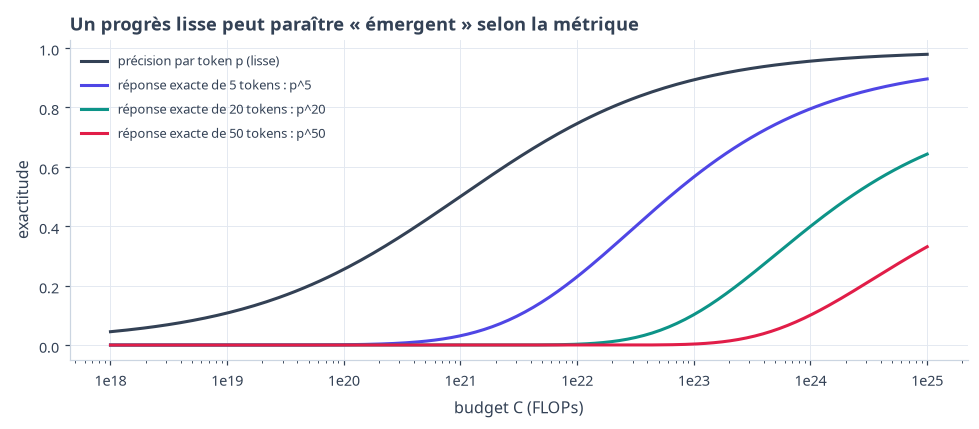

In [20]:
logC = np.linspace(18, 25, 200)
p_tok = 1 / (1 + np.exp(-(logC - 21) * 1.1)) * 0.98 + 0.01   # progrès lisse par token
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(10 ** logC, p_tok, color=SLATE, label="précision par token p (lisse)")
for k, c in [(5, INDIGO), (20, TEAL), (50, ROSE)]:
    ax.plot(10 ** logC, p_tok ** k, color=c, label=f"réponse exacte de {k} tokens : p^{k}")
ax.set_xscale("log"); m.plain_log_axis(ax, fmt=sci)
ax.set_xlabel("budget C (FLOPs)"); ax.set_ylabel("exactitude")
ax.set_title("Un progrès lisse peut paraître « émergent » selon la métrique"); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

> **À retenir.** Les lois d'échelle permettent de prévoir la perte, mais l'extrapolation
> sur plusieurs ordres de grandeur est fragile, et les capacités mesurées par des
> métriques en « tout ou rien » peuvent sembler apparaître brutalement.

## 9. Les goulots d'étranglement : données et électricité (section *Scaling bottlenecks*)

De GPT-1 (117 millions de paramètres) à GPT-3 (175 milliards), la taille a crû de trois
ordres de grandeur en trois ans. Deux limites sont déjà visibles.

**Les données.** Les jeux d'entraînement grossissent bien plus vite que la production de
nouveaux textes humains (Villalobos et al.). Ci-dessous, la taille des corpus de
quelques modèles et une tendance exponentielle, face à un ordre de grandeur du **stock**
de texte humain public de qualité (environ 300 000 milliards de tokens selon
l'estimation centrale de Villalobos et al., 2024, avec une forte incertitude).

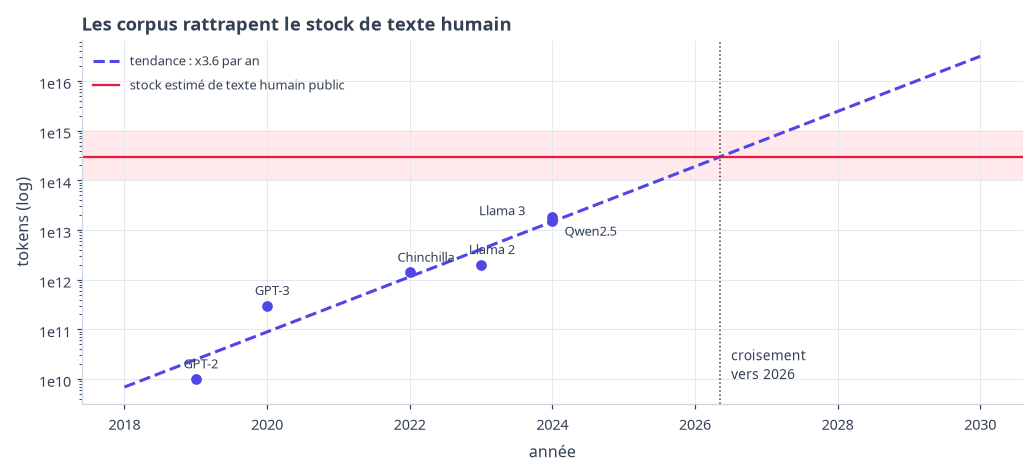

In [21]:
data_pts = pd.DataFrame([("GPT-2", 2019, 10e9), ("GPT-3", 2020, 300e9), ("Chinchilla", 2022, 1.4e12),
                         ("Llama 2", 2023, 2e12), ("Llama 3", 2024, 15e12), ("Qwen2.5", 2024, 18e12)],
                        columns=["modèle", "année", "tokens"])
coef = np.polyfit(data_pts.année, np.log10(data_pts.tokens), 1)
years = np.arange(2018, 2031)
trend = 10 ** np.polyval(coef, years)
stock, stock_lo, stock_hi = 300e12, 100e12, 1000e12
cross = (np.log10(stock) - coef[1]) / coef[0]
fig, ax = plt.subplots(figsize=(9.5, 4.4))
ax.semilogy(years, trend, color=INDIGO, ls="--", label=f"tendance : x{10 ** coef[0]:.1f} par an")
ax.semilogy(data_pts.année, data_pts.tokens, "o", color=INDIGO)
offs = {"Llama 3": (-48, 4), "Qwen2.5": (8, -12)}
for _, r in data_pts.iterrows():
    ax.annotate(r.modèle, (r.année, r.tokens), xytext=offs.get(r.modèle, (-8, 7)), textcoords="offset points",
                fontsize=8.5)
ax.axhspan(stock_lo, stock_hi, color=LIGHT[ROSE], alpha=0.8)
ax.axhline(stock, color=ROSE, lw=1.5, label="stock estimé de texte humain public")
ax.axvline(cross, color=SLATE, lw=1, ls=":")
ax.text(cross + 0.15, 1e10, f"croisement\nvers {cross:.0f}", fontsize=9)
ax.set_xlabel("année"); ax.set_ylabel("tokens (log)"); m.plain_log_axis(ax, "y", sci)
ax.set_title("Les corpus rattrapent le stock de texte humain"); ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout(); plt.show()

Le croisement exact dépend d'hypothèses très incertaines (Villalobos et al. situent
l'épuisement du stock entre 2026 et 2032), mais le message est clair : pour les plus
grands modèles, il est imminent. D'où plusieurs phénomènes décrits par le livre :

- tout ce qui est publié en ligne finit dans des données d'entraînement, ce qui ouvre la
  porte à l'injection délibérée de contenus (et aux attaques du chapitre 5) ; faire
  « oublier » une information à un modèle reste un problème ouvert ;
- le web se remplit de textes **générés par IA** (et traduits automatiquement), dont
  l'effet sur les futurs modèles est discuté au chapitre 8 ;
- les **données propriétaires** (livres, contrats, dossiers médicaux...) deviennent un
  avantage compétitif, et les sites restreignent l'accès : selon Longpre et al. (2024),
  45 % de C4 est désormais soumis à restrictions.

**L'électricité.** Les centres de données consomment 1 à 2 % de l'électricité mondiale,
peut-être 4 à 20 % en 2030 : sans nouvelles capacités de production, ils ne pourront
croître que d'un facteur 50 environ, moins de deux ordres de grandeur. Ordre de grandeur
pour GPT-3, avec des H100 à 50 % d'utilisation et environ 0,7 kW par GPU :

In [22]:
gpu_hours = C_gpt3 / (peak * 0.5) / 3600
energy_mwh = gpu_hours * 0.7 / 1000
print(f"heures-GPU : {gpu_hours / 1e6:.1f} millions ; énergie GPU seule : {energy_mwh:,.0f} MWh".replace(",", " "))
print(f"soit la consommation électrique annuelle d'environ {energy_mwh / 4.5:.0f} foyers (4,5 MWh/an)")

heures-GPU : 2.9 millions ; énergie GPU seule : 2 035 MWh
soit la consommation électrique annuelle d'environ 452 foyers (4,5 MWh/an)


Et ce chiffre ignore le refroidissement, les expériences préalables et surtout
l'inférence, qui sur la durée de vie d'un modèle populaire dépasse largement
l'entraînement.

> **À retenir.** La croissance des modèles bute sur deux ressources finies : le texte
> humain de qualité (bientôt épuisé, d'où données propriétaires et synthétiques) et
> l'énergie (dont la production ne peut pas suivre une croissance exponentielle).

## Synthèse

- **Paramètres.** $N \approx L(4d^2 + 3d\,d_{ff}) + Vd$ ; notre fonction retrouve à
  l'unité près GPT-2, Qwen2.5, Llama et Mixtral. Les petits modèles consacrent une part
  importante de leurs paramètres au vocabulaire.
- **Mémoire.** Poids : $N \cdot b$ octets ; cache KV : $2Lh_{kv}d_hTBb$, qui peut
  dépasser les poids pour les longs contextes. GQA et MoE sont des réponses d'ingénierie
  à ces coûts.
- **Inférence.** Prefill parallèle, decode séquentiel et limité par la mémoire.
- **Alternatives.** SSM, Mamba, RWKV : mémoire constante et coût linéaire en longueur ;
  hybrides comme Jamba.
- **Calcul.** $C \approx 6ND$ ; durée et coût se déduisent du débit crête, de
  l'utilisation et du prix horaire.
- **Chinchilla.** À budget fixé, environ 20 tokens par paramètre ; en production, le
  coût d'inférence pousse vers des modèles plus petits et sur-entraînés.
- **Limites.** Extrapolation fragile, capacités « émergentes », données humaines bientôt
  épuisées, énergie.

**Liens.** Le chapitre 7 calcule la mémoire d'entraînement et de finetuning et présente
la quantification ; le chapitre 8 traite des données (qualité, synthèse) ; le chapitre 9
exploite prefill, decode et cache KV pour optimiser l'inférence. Le cours 3 aborde
l'étape suivante du cycle de vie : le post-entraînement.

In [23]:
llm.free_gpu()